Constanza Pontillo 21.981.293-0

In [58]:
import numpy as np#Importamos las librerias a utilizar
import matplotlib.pyplot as plt

In [59]:
rng = np.random.default_rng(seed = 33)#Elegimos semilla

In [60]:
"Estos son los datos que nos aporta el enunciado"
x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)

X, Y = np.meshgrid(x, y)#Cada posision tiene una coordenada

Nestrellas = 5 
I0 = 100#Intensidad maxima
sigma = 0.5#Determina la dispersion espacial de su intensidad
x0 = rng.uniform(-5, 5 , Nestrellas)
y0 = rng.uniform(-5, 5 , Nestrellas)

In [61]:
imagen = np.zeros_like(X)#Hacemos una imagen en blanco para empezar

#El el ciclo for tomamos cada estrella y aplicamos la fromula que nos dan para obtener la intensidad y esta la sumamos a la imagen que es -por asi decir- nuestro lienzo "

for i in range(Nestrellas):
    intensidad = I0 * np.exp(-((X - x0[i])**2 + (Y - y0[i])**2) / (2 * sigma**2))
    imagen += intensidad

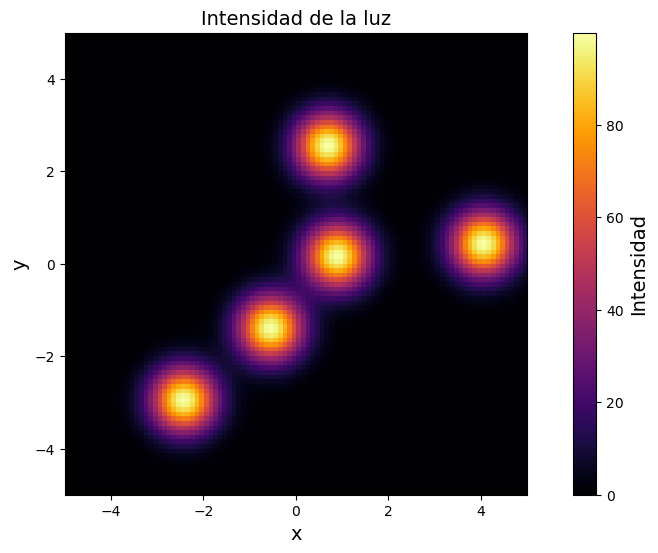

In [62]:
plt.figure(figsize=(12,6))#Eligimos el tamaño de nuestra grafica

im = plt.imshow(imagen,origin="lower",extent=[-5,5,-5,5],cmap="inferno")#Hacemos un llamado a nuestra barra con las intensidades
cbar = plt.colorbar(im)
cbar.set_label("Intensidad", fontsize=14)#Le ponemos nombre y el tamaño de letra lo ajustamos

plt.xlabel("x", fontsize=14)#Ponemos nombre al eje x, y tambien ajustamos el tamaño de la letra
plt.ylabel("y", fontsize=14)#Ponemos nombre al eje y e tambien ajustamos el tamaño de la letra
plt.title("Intensidad de la luz", fontsize=14)#Ponemos titulo al grafico

plt.show()#Lo mostramos

In [63]:
#Esta funcion le daremos la distancia de los centros y nos la devolvera las distancias entre cada estrellas

def dist_euclidianas(x0,y0):#Pedimos los arreglos x0 e y0
    cant = len(x0)#Esto es meramente por si no sabemos la cantidad de estrellas y hacerlo mas generico y no espeficico para un solo caso
    distancias = np.zeros((cant,cant))#Volvemos a generar un linezo con puros ceros 

    for i in range(cant):#Recorrenos cada estrella
        for j in range(cant):
            distancias[i,j] = np.sqrt((x0[i] - x0[j])**2 + (y0[i] - y0[j])**2)#Aplicamos formula para tener las distancias

    return distancias#Retornamos las distancias

distancia = dist_euclidianas(x0, y0)#Probamos que funcione
print(distancia)

[[0.         4.16407324 4.99556607 2.46030065 2.13795875]
 [4.16407324 0.         4.0104849  6.37168957 2.41123534]
 [4.99556607 4.0104849  0.         7.37420428 3.20458043]
 [2.46030065 6.37168957 7.37420428 0.         4.58825184]
 [2.13795875 2.41123534 3.20458043 4.58825184 0.        ]]


Text(0.5, 1.0, 'Menor a mayor intensidad')

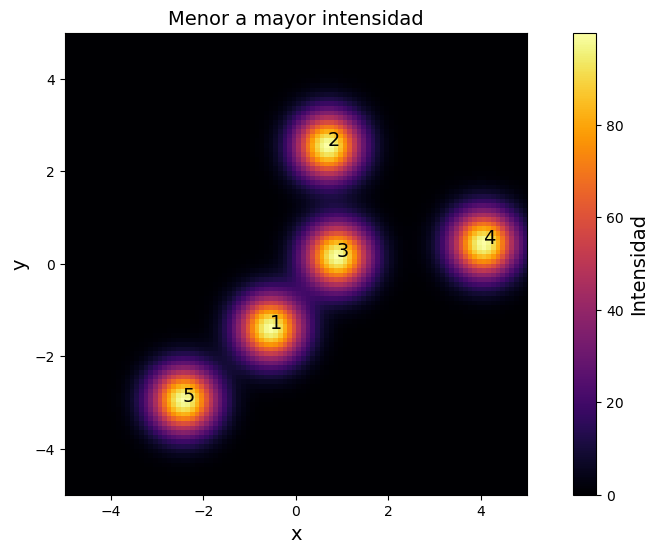

In [64]:
intensidad = []#Haremos esta lista para guardar cada intensidad que obtengamos
for i in range(Nestrellas):#Recorremos cada estrella que tengamos 
    idx_x = np.argmin((np.abs(x - x0[i])))#Obtendremos los indices
    idx_y = np.argmin((np.abs(y - y0[i])))
    intensidad.append(imagen[idx_y, idx_x])#Agregaamos los indices a nuestra lista

ordenadas = np.argsort(intensidad)#Las ordenamos de menor a mayor por medio de las funciones de np

plt.figure(figsize=(12,6))#Elegimos el tamaño de la imagen
im = plt.imshow(imagen,origin="lower",extent=[-5,5,-5,5],cmap="inferno")#Hacemos un llamado a nuestra barra con las intensidades
cbar = plt.colorbar(im)
cbar.set_label("Intensidad", fontsize=14)#Cambiamos de nombre y de tamaño de letra

for lugar, idx in enumerate(ordenadas, start=1):#Colocamos el numero en cada estrella
    plt.text(x0[idx], y0[idx], str(lugar), color="black", fontsize=14)

plt.xlabel("x", fontsize=14)#Ponemos nombre al eje x, y tambien ajustamos el tamaño de la letra
plt.ylabel("y", fontsize=14)#Ponemos nombre al eje y e tambien ajustamos el tamaño de la letra
plt.title("Menor a mayor intensidad", fontsize=14)#Ponemos el titulo

In [65]:
sigma = [0.25, 0.50, 0.75, 1.0]#Elegimos los valores que tendra sigma
posicion = [(0,0), (0,1), (1,0), (1,1)]#Designamos cada region a cada sigma

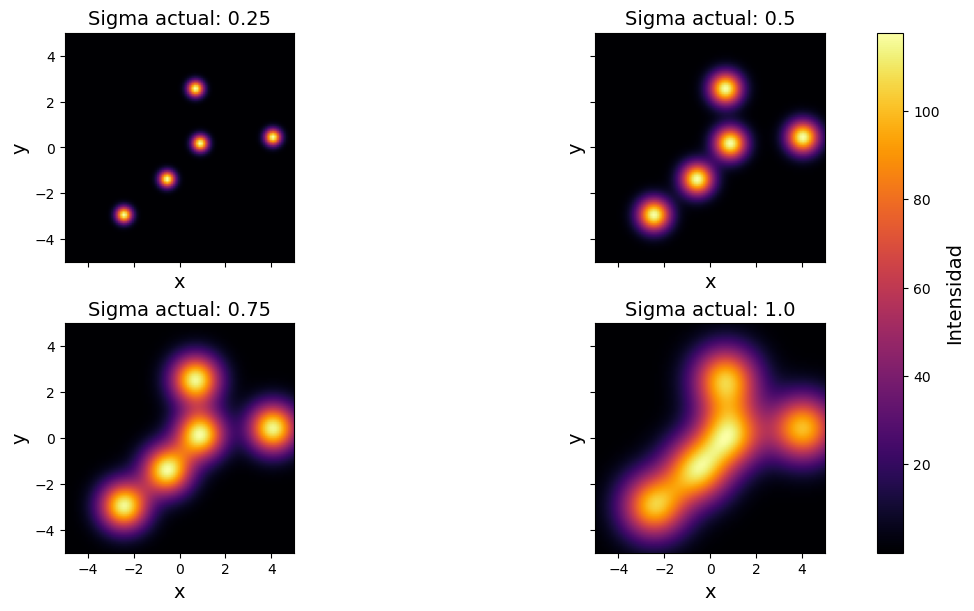

In [66]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6),sharex=True,sharey=True,constrained_layout=True)

for i in range(4):
    sigma_actual = sigma[i]#Elegimos un sigma 
    fila, columna = posicion[i]#Lo ubicamos 
    ax = axs[fila,columna]

    imagen_sigma = np.zeros_like(X)#Tenemos nuestro lienzo
    
    for j in range(Nestrellas):#Recorremos cada estrella y le calculamos la insidad con el sigma del momento
        intensidad_sigma = I0 * np.exp(-((X - x0[j])**2 + (Y - y0[j])**2) / (2 * sigma_actual**2))#Usamos la formula
        imagen_sigma += intensidad_sigma#Lo agregamos a la imagen 

    im = ax.imshow(imagen_sigma,origin="lower",extent=[-5,5,-5,5],cmap="inferno")#Nuevamente ponemos nuestra barra de intensidades

    "Esto esta dentro del for ya qeu cambia al menos el titulo para cada caso de sigma"
    ax.set_xlabel("x", fontsize=14)#Cambiamos lo nombres del eje y el tamaño de la letra 
    ax.set_ylabel("y", fontsize=14)#Cambiamos lo nombres del eje y el tamaño de la letra 
    ax.set_title(f"Sigma actual: {sigma_actual}", fontsize=14)#Ponemos titulo 

"Esto esta afuera del for porque es una para todos"
cbar = fig.colorbar(im, ax=axs, location="right",shrink=1.)#Establecemos lugar de la barra
cbar.set_label("Intensidad", fontsize=14)#Cambiamos de nombre y tamaño de letra de la barra

plt.show()#Mostramos

Podemos notar que a medida cambia el sigma que es el encargado de determianr la dispercion espacial de su intensidad. Al aumentar sigma las estrellas se difuminan y se superponen entre ellas.